# Complete analysis
In this notebook we combine the results the `tapo-analyis-conf1.ipynb` and `comparison_analysis.ipynb`.

## pipeline configurations
One pipeline configuration: `power-stress-2`

The pipeline config was run *4* times.

## time shifts
* There is a time difference of 120 minutes between the Tapo measurement and Simpipe. In argo workflows the time seem to be correct, but simpipe has an internal clock which is 2hrs early.
* `surge_time_diff` is the measured time diff between the start time of the Tapo energy surge identified, and what SIMPIPE provides as timestamp. (this is what we use to shift the data) - No significant shift was noted in these data.

In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from analysis_functions import get_time_periods, get_power_data, divide_power_data_into_step_periods, compute_relative_energy_usage, compute_baseline_stats

In [2]:
surge_time_diffs = pd.read_csv("../../data/power-stress-2/surge_time_diffs.dat", sep=r'\s+', comment='#', header=0)

In [3]:
surge_time_diffs.head(4)

,configuration,runNr,startDiff,endDiff,duration
0,power-surge,1,0.06,-0.03,180.1
1,power-surge,2,0.08,-0.01,180.1
2,power-surge,3,0.06,-0.03,180.1
3,power-surge,4,0.08,0.00,180.1


In [4]:
base_path = "../../data/power-stress-2"
datasets = {
    "conf-1": {
        "simpipe_datetime_shift": 0.00, # shift simpipe_data by this amount of minutes (from comparison_analysis.ipynb average Delta value)
        "run1": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "power-surge"][surge_time_diffs.runNr == 1].values[0][2]),
            "start_time_baseline": '2026-09-28 00:00:00',
            "end_time_baseline": '2026-09-28 10:26:33',
            "start_time_pipeline": '2026-09-28 10:26:33',
            "end_time_pipeline": '2026-09-28 13:26:37'
            },
        "run2": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "power-surge"][surge_time_diffs.runNr == 2].values[0][2]),
            "start_time_baseline": '2026-09-28 18:30:00',
            "end_time_baseline": '2026-09-29 06:00:00',
            "start_time_pipeline": '2026-09-28 15:26:33',
            "end_time_pipeline": '2026-09-28 18:26:33'
            },
        "run3": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "power-surge"][surge_time_diffs.runNr == 3].values[0][2]),
            "start_time_baseline": '2026-09-28 20:00:00',
            "end_time_baseline": '2026-09-29 10:56:32',
            "start_time_pipeline": '2026-09-29 10:56:26',
            "end_time_pipeline": '2026-09-29 13:56:32'
            },
        "run4": {
            "surge_time_diff": float(surge_time_diffs[surge_time_diffs.configuration == "power-surge"][surge_time_diffs.runNr == 4].values[0][2]),
            "start_time_baseline": '2026-09-30 14:00:00',
            "end_time_baseline": '2026-10-01 08:50:14',
            "start_time_pipeline": '2026-10-01 08:50:14',
            "end_time_pipeline": '2026-10-01 11:50:14'},
    }
}

In [5]:
def analyze_data(
        simpipe_data: pd.DataFrame,
        tapo_power_data: pd.DataFrame,
        simpipe_datetime_shift: float = 0,
        start_time_baseline: str = None,
        end_time_baseline: str = None):
    """
    Analyze the data from the simulation pipe and Tapo power data.

    Baseline energy comes in two flavours (see analysis_functions.compute_relative_energy_usage):
    - tapo_be: baseline energy PER TAPO SAMPLE (kWh/sample) -- a rate, not a total.
    - tapo_BE: baseline energy TOTALED over the surge/pipeline window (kWh), i.e.
      tapo_be * n_samples. This is the quantity comparable to AE and RE: AE == BE + RE.
    """
    if simpipe_datetime_shift != 0:
        simpipe_data = simpipe_data.copy()
        # Convert start and stop columns to datetime if they aren't already
        simpipe_data["start"] = pd.to_datetime(simpipe_data["start"])
        simpipe_data["stop"] = pd.to_datetime(simpipe_data["stop"])
        # Apply shift
        simpipe_data["start"] += pd.Timedelta(minutes=simpipe_datetime_shift)
        simpipe_data["stop"] += pd.Timedelta(minutes=simpipe_datetime_shift)

    tapo_time_periods = get_time_periods(simpipe_data, start_date_baseline=start_time_baseline, end_date_baseline=end_time_baseline)
    tapo_baseline_stats = compute_baseline_stats(df=tapo_power_data, percentile_threshold=70, print_stats=True) # compute baseline stats automatically.
    tapo_segmented_power_data = divide_power_data_into_step_periods(tapo_time_periods, tapo_power_data)
    tapo_relative_energy_usage, tapo_be, tapo_total_absolute_energy, tapo_total_relative_energy = compute_relative_energy_usage(tapo_segmented_power_data, tapo_time_periods, tapo_baseline_stats)
    # BE: baseline energy totaled over the surge/pipeline window -- comparable to AE and RE (AE == BE + RE)
    tapo_BE = tapo_relative_energy_usage["BE(kWh)"].sum() if not tapo_relative_energy_usage.empty else 0
    return {
        "time_periods": tapo_time_periods,
        "tapo_segmented_power_data": tapo_segmented_power_data,
        "tapo_relative_energy_usage": tapo_relative_energy_usage,
        "tapo_be": tapo_be,
        "tapo_BE": tapo_BE,
        "tapo_total_absolute_energy": tapo_total_absolute_energy,
        "tapo_total_relative_energy": tapo_total_relative_energy,
        "simpipe_data": simpipe_data,
        "simpipe_total_energy": simpipe_data["energy"].sum(),
        "simpipe_pipeline_duration": (simpipe_data["stop"] - simpipe_data["start"]).sum().total_seconds()
    }

In [6]:
# Compute results

results = {
    "conf-1": [],

}
for confNr in ["conf-1"]:
    print()
    print(f"=== PROCESSING {confNr} ===")
    for runNr in ["run1", "run2", "run3", "run4"]:
        print()
        print(f"  --- Processing {runNr}...")
        path_simpipe_data = f"{base_path}/{runNr}.dat"
        path_tapo_data = f"{base_path}/power-{runNr}.xls"
        simpipe_data = pd.read_csv(path_simpipe_data, sep=r'\s+', comment='#', header=0)
        if simpipe_data["energy"].dtype == 'object':
            raise ValueError(f"Invalid data type for energy column in {path_simpipe_data}")
        tapo_power_data = get_power_data(path_tapo_data) # get tapo power data
        tapo_power_data = tapo_power_data.assign(
            **{"Power(W)": pd.to_numeric(tapo_power_data["Power(W)"]).astype(float)}
        )
        #simpipe_datetime_shift = datasets[confNr]["simpipe_datetime_shift"]
        simpipe_datetime_shift = datasets[confNr][runNr]["surge_time_diff"]
        start_time_baseline = datasets[confNr][runNr]["start_time_baseline"]
        end_time_baseline = datasets[confNr][runNr]["end_time_baseline"]
        r = analyze_data(
            simpipe_data=simpipe_data,
            tapo_power_data=tapo_power_data,
            simpipe_datetime_shift=simpipe_datetime_shift,
            start_time_baseline=start_time_baseline,
            end_time_baseline=end_time_baseline)
        results[confNr].append({"confNr": confNr, "runNr": runNr, **r})


=== PROCESSING conf-1 ===

  --- Processing run1...
    get_time_periods -- start and end times present. Assuming baseline period.
     appending baseline period
    get_time_periods -- extracted time periods:
      - baseline: 2026-09-28 00:00:00 to 2026-09-28 10:26:33
      - power-stress(0:0): 2026-09-28 08:26:36 to 2026-09-28 11:26:40
     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 210.0 W
      Baseline periods: 210 out of 288 (72.9%)
      Mean baseline power: 205.5 W
      Median baseline power: 205.0 W
      Std baseline power: 2.6 W
      Power range: 200.0 - 210.0 W
      Mean baseline energy per period: 0.017123 kWh
      Total baseline energy: 3.5958 kWh


     divide_power_data_into_step_periods...
        Processing baseline...
            start: 2026-09-28 00:00:00, end: 2026-09-28 10:26:33
        Setting baseline energy and power values from baseline step.
        Processing power-stress(0:0)...
            start: 2026-09-28 08:

In [7]:
# Analyse the results
final_results = pd.DataFrame(
    columns=["conf", "tapo_be_avg", "tapo_be_std", "tapo_BE_avg", "tapo_BE_std", "tapo_absolute_energy_avg", "tapo_absolute_energy_std", "tapo_relative_energy_avg", "tapo_relative_energy_std", "simpipe_energy_avg", "simpipe_energy_std", "simpipe_duration_avg", "simpipe_duration_std"]
)
final_results_details = pd.DataFrame(
    columns=["conf", "runNr", "tapo_be", "tapo_BE", "tapo_total_relative_energy", "tapo_total_absolute_energy", "simpipe_total_energy", "simpipe_duration"]
)
print("=== Analysis of the results ==================================================================")
print("""
    be  = Baseline Energy rate (kWh per Tapo sample) -- NOT a window total
    BE  = Baseline Energy totaled over the surge/pipeline window (kWh) = be * n_samples
    RE  = Relative Tapo Energy, above baseline, over the surge/pipeline window (kWh)
    AE  = Absolute Tapo Energy over the surge/pipeline window (kWh)
    SE  = SIMPIPE Energy (kWh)
    SD  = SIMPIPE Duration

    Identity: AE == BE + RE  (both expressed as window totals, in kWh)
""")
for conf in results:
    print()
    print(f"=== RESULTS FOR {conf} ==================================================================")
    print("    Run :    be       BE       RE       AE     BE+RE      SE       |   SD")
    print("-----------------------------------------------------------------------------------------")
    be_rates = [result['tapo_be'] for result in results[conf]]
    baseline_energies = [result['tapo_BE'] for result in results[conf]]
    tapo_relative_energies = [result['tapo_total_relative_energy'] for result in results[conf]]
    tapo_absolute_energies = [result['tapo_total_absolute_energy'] for result in results[conf]]
    simpipe_energies = [result['simpipe_total_energy'] for result in results[conf]]
    simpipe_durations = [result['simpipe_pipeline_duration'] for result in results[conf]]

    avg_be_rate = np.mean(be_rates)
    avg_baseline_energy = np.mean(baseline_energies)
    avg_tapo_absolute_energy = np.mean(tapo_absolute_energies)
    avg_tapo_relative_energy = np.mean(tapo_relative_energies)
    avg_simpipe_energy = np.mean(simpipe_energies)
    avg_simpipe_duration = np.mean(simpipe_durations)

    std_be_rate = np.std(be_rates)
    std_baseline_energy = np.std(baseline_energies)
    std_tapo_absolute_energy = np.std(tapo_absolute_energies)
    std_tapo_relative_energy = np.std(tapo_relative_energies)
    std_simpipe_energy = np.std(simpipe_energies)
    std_simpipe_duration = np.std(simpipe_durations)

    final_results = pd.concat([final_results, pd.DataFrame([{
        "conf": conf,
        "tapo_be_avg": avg_be_rate,
        "tapo_be_std": std_be_rate,
        "tapo_BE_avg": avg_baseline_energy,
        "tapo_BE_std": std_baseline_energy,
        "tapo_absolute_energy_avg": avg_tapo_absolute_energy,
        "tapo_absolute_energy_std": std_tapo_absolute_energy,
        "tapo_relative_energy_avg": avg_tapo_relative_energy,
        "tapo_relative_energy_std": std_tapo_relative_energy,
        "simpipe_energy_avg": avg_simpipe_energy,
        "simpipe_energy_std": std_simpipe_energy,
        "simpipe_duration_avg": avg_simpipe_duration,
        "simpipe_duration_std": std_simpipe_duration
    }])], ignore_index=True)

    for result in results[conf]:
        final_results_details = pd.concat([final_results_details, pd.DataFrame([{
            "conf": conf,
            "runNr": result['runNr'],
            "tapo_be": result['tapo_be'],
            "tapo_BE": result['tapo_BE'],
            "tapo_total_relative_energy": result['tapo_total_relative_energy'],
            "tapo_total_absolute_energy": result['tapo_total_absolute_energy'],
            "simpipe_total_energy": result['simpipe_total_energy'],
            "simpipe_duration": result['simpipe_pipeline_duration']
        }])], ignore_index=True)

        be_plus_re = result['tapo_BE'] + result['tapo_total_relative_energy']
        print(f"    {result['runNr']} : {result['tapo_be']:.4f}   {result['tapo_BE']:.4f}  {result['tapo_total_relative_energy']:.4f}  {result['tapo_total_absolute_energy']:.4f}  {be_plus_re:.4f}  {result['simpipe_total_energy']:.4f}     |   {result['simpipe_pipeline_duration']:.1f} seconds (in {result['simpipe_pipeline_duration']/3600:.2f} hours)")
    print("-----------------------------------------------------------------------------------------")
    avg_be_plus_re = avg_baseline_energy + avg_tapo_relative_energy
    print(f"    AVG : {avg_be_rate:.4f}   {avg_baseline_energy:.4f}  {avg_tapo_relative_energy:.4f}  {avg_tapo_absolute_energy:.4f}  {avg_be_plus_re:.4f}  {avg_simpipe_energy:.4f}     |   {avg_simpipe_duration:.1f} seconds (in {avg_simpipe_duration/3600:.2f} hours)")
    print(f"    STD : {std_be_rate:.4f}   {std_baseline_energy:.4f}  {std_tapo_relative_energy:.4f}  {std_tapo_absolute_energy:.4f}            {std_simpipe_energy:.4f}     |   {std_simpipe_duration:.1f} seconds (in {std_simpipe_duration/3600:.2f} hours)")
    print("=========================================================================================")

=== Analysis of the results ==================================================================

    be  = Baseline Energy rate (kWh per Tapo sample) -- NOT a window total
    BE  = Baseline Energy totaled over the surge/pipeline window (kWh) = be * n_samples
    RE  = Relative Tapo Energy, above baseline, over the surge/pipeline window (kWh)
    AE  = Absolute Tapo Energy over the surge/pipeline window (kWh)
    SE  = SIMPIPE Energy (kWh)
    SD  = SIMPIPE Duration

    Identity: AE == BE + RE  (both expressed as window totals, in kWh)


=== RESULTS FOR conf-1 ==================================================================
    Run :    be       BE       RE       AE     BE+RE      SE       |   SD
-----------------------------------------------------------------------------------------
    run1 : 0.0171   0.6164  0.0139  0.6303  0.6303  0.4269     |   10804.0 seconds (in 3.00 hours)
    run2 : 0.0172   0.6181  0.0180  0.6361  0.6361  0.4270     |   10807.0 seconds (in 3.00 hours)
    

In [8]:
final_results

,conf,tapo_be_avg,tapo_be_std,tapo_BE_avg,tapo_BE_std,tapo_absolute_energy_avg,tapo_absolute_energy_std,tapo_relative_energy_avg,tapo_relative_energy_std,simpipe_energy_avg,simpipe_energy_std,simpipe_duration_avg,simpipe_duration_std
0,conf-1,0.017136,0.000024,0.61691,0.000868,0.630704,0.00448,0.013794,0.003654,0.426953,0.000054,10805.75,1.089725


In [9]:
final_results_details

,conf,runNr,tapo_be,tapo_BE,tapo_total_relative_energy,tapo_total_absolute_energy,simpipe_total_energy,simpipe_duration
0,conf-1,run1,0.017123,0.616429,0.013905,0.630333,0.426861,10804.0
1,conf-1,run2,0.017169,0.618087,0.018021,0.636108,0.426991,10807.0
2,conf-1,run3,0.017106,0.615802,0.008011,0.623813,0.426993,10806.0
3,conf-1,run4,0.017148,0.617324,0.015238,0.632562,0.426968,10806.0


In [10]:
final_results.to_csv("../../data/power-stress-2/final_results.csv", index=False)
final_results_details.to_csv("../../data/power-stress-2/final_results_details.csv", index=False)

In [11]:
final_results_details.tapo_be.mean()  # be: baseline energy rate (kWh/sample)

np.float64(0.017136398970904874)

In [12]:
final_results_details.tapo_total_relative_energy.mean()  # RE

np.float64(0.01379359538075781)

In [13]:
final_results_details.tapo_total_absolute_energy.mean()  # AE

np.float64(0.6307039583333331)

In [14]:
print("tapo_BE mean (baseline energy totaled over window):", final_results_details.tapo_BE.mean())
print("tapo_BE + RE  mean:", (final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy).mean())
print("tapo_AE       mean:", final_results_details.tapo_total_absolute_energy.mean())
print("Check AE == BE + RE per run:")
final_results_details.assign(
    be_plus_re=final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy,
    ae_minus_be_plus_re=final_results_details.tapo_total_absolute_energy - (final_results_details.tapo_BE + final_results_details.tapo_total_relative_energy)
)[["runNr", "tapo_BE", "tapo_total_relative_energy", "be_plus_re", "tapo_total_absolute_energy", "ae_minus_be_plus_re"]]

tapo_BE mean (baseline energy totaled over window): 0.6169103629525754
tapo_BE + RE  mean: 0.6307039583333334
tapo_AE       mean: 0.6307039583333331
Check AE == BE + RE per run:


,runNr,tapo_BE,tapo_total_relative_energy,be_plus_re,tapo_total_absolute_energy,ae_minus_be_plus_re
0,run1,0.616429,0.013905,0.630333,0.630333,-0.0
1,run2,0.618087,0.018021,0.636108,0.636108,-0.0
2,run3,0.615802,0.008011,0.623812,0.623813,0.0
3,run4,0.617324,0.015238,0.632562,0.632562,-0.0


In [15]:
final_results_details.simpipe_total_energy.mean()

np.float64(0.42695325)

<Axes: xlabel='Run number', ylabel='Energy (kWh)'>

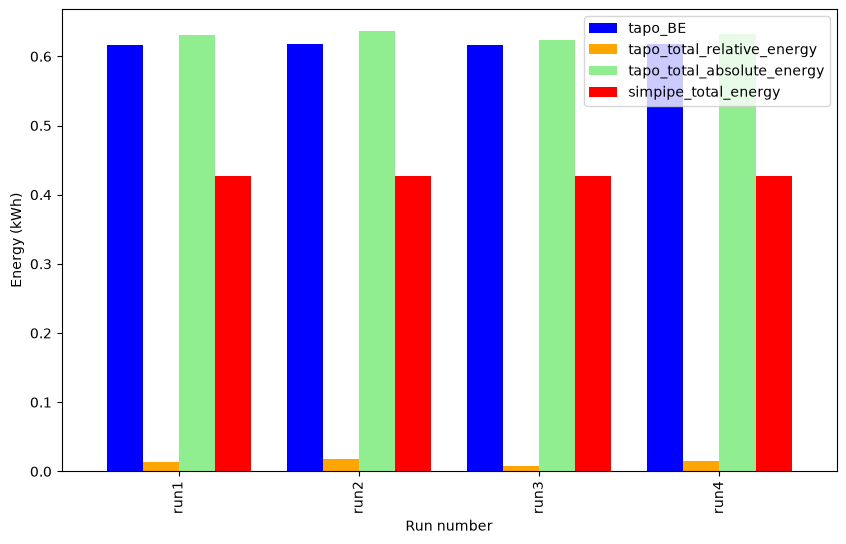

In [16]:
final_results_details.plot(x='runNr', y=['tapo_BE', 'tapo_total_relative_energy', 'tapo_total_absolute_energy', 'simpipe_total_energy'], kind='bar', ylabel="Energy (kWh)", xlabel="Run number", figsize=(10, 6), width=0.8, color=['blue', 'orange', 'lightgreen', 'red'])

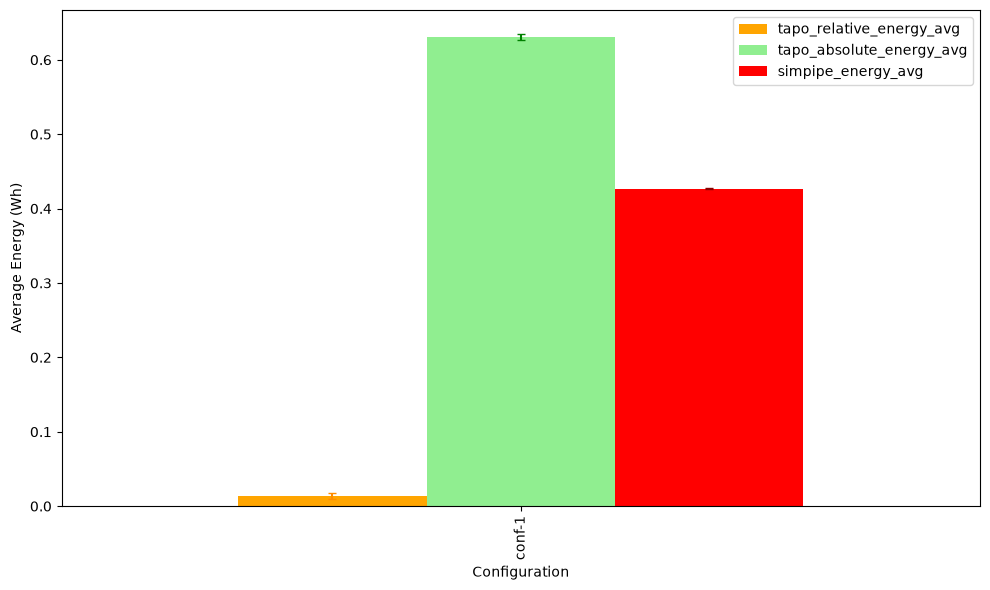

In [ ]:
import matplotlib.pyplot as plt

# Create the bar plot
ax = final_results.plot(x='conf', y=['tapo_relative_energy_avg', 'tapo_absolute_energy_avg', 'simpipe_energy_avg'],
                       kind='bar', ylabel="Average Energy (kWh)", xlabel="Configuration",
                       figsize=(10, 6), width=0.8, color=['orange', 'lightgreen', 'red'])

# Add error bars
x_pos = np.arange(len(final_results))
width = 0.8 / 3  # width of each bar divided by number of series
#offset = width * 1.5  # offset for positioning bars

# Error bars for each series with correct positioning
ax.errorbar(x_pos - width, final_results['tapo_relative_energy_avg'],
           yerr=final_results['tapo_relative_energy_std'], fmt='none', color='darkorange', capsize=3)
ax.errorbar(x_pos, final_results['tapo_absolute_energy_avg'],
           yerr=final_results['tapo_absolute_energy_std'], fmt='none', color='green', capsize=3)
ax.errorbar(x_pos + width, final_results['simpipe_energy_avg'],
           yerr=final_results['simpipe_energy_std'], fmt='none', color='darkred', capsize=3)

plt.tight_layout()
plt.show()